In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-{:02d}.parquet"
USECOLS = [
    "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "trip_distance", "PULocationID", "DOLocationID",
    "fare_amount", "total_amount",
]
df = pd.concat(
    (pd.read_parquet(URL.format(m), columns=USECOLS) for m in range(1, 13)),
    ignore_index=True,
)
n_raw = len(df)


In [2]:
pickup = df["tpep_pickup_datetime"]
df["pickup_hour"] = pickup.dt.hour
df["pickup_month"] = pickup.dt.month
df["pickup_day"] = pickup.dt.day
df["duration_min"] = (df["tpep_dropoff_datetime"] - pickup).dt.total_seconds() / 60
speed_mph = df["trip_distance"] / (df["duration_min"] / 60)

mask = (
    (pickup.dt.year == 2025)
    & (df["duration_min"] >= 1)
    & df["trip_distance"].between(0.2, 25)
    & df["fare_amount"].between(0.01, 100)
    & (df["total_amount"] <= 125)
    & (speed_mph > 0) & (speed_mph <= 40)
)

final = df.loc[mask, [
    "VendorID", "PULocationID", "DOLocationID",
    "pickup_hour", "pickup_month", "pickup_day",
    "trip_distance", "duration_min", "fare_amount",
]].copy()
final["fare_per_mile"] = final["fare_amount"] / final["trip_distance"]  # EDA only, NOT a model feature
del df, pickup, speed_mph, mask
print(f"Rows kept: {len(final):,} ({len(final) / n_raw:.1%} of {n_raw:,})")
assert final.isna().sum().sum() == 0

Rows kept: 43,426,429 (89.1% of 48,722,602)


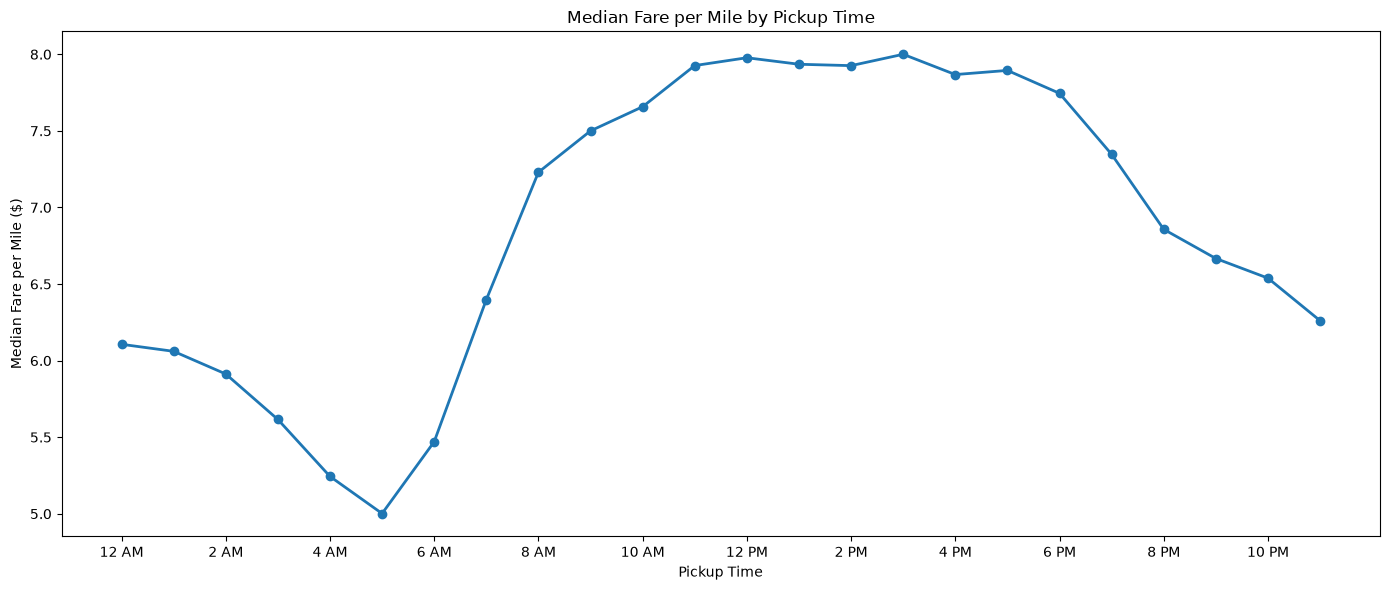

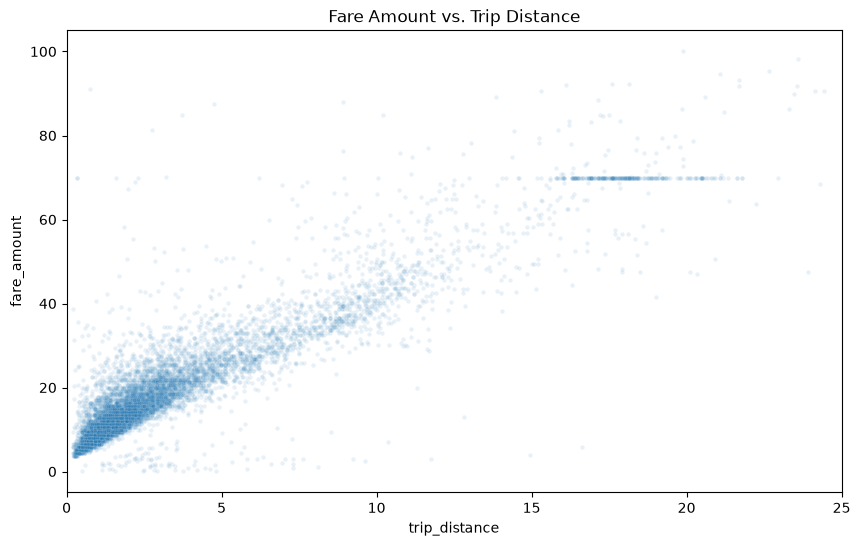

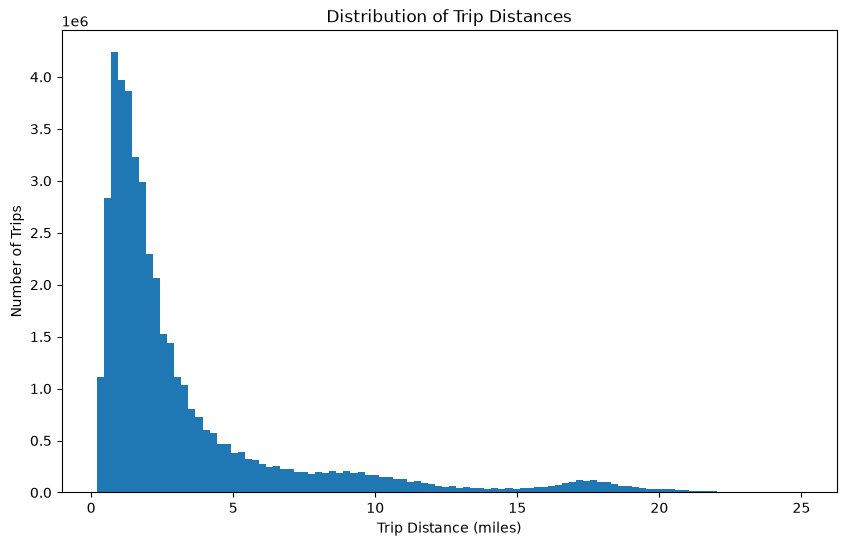

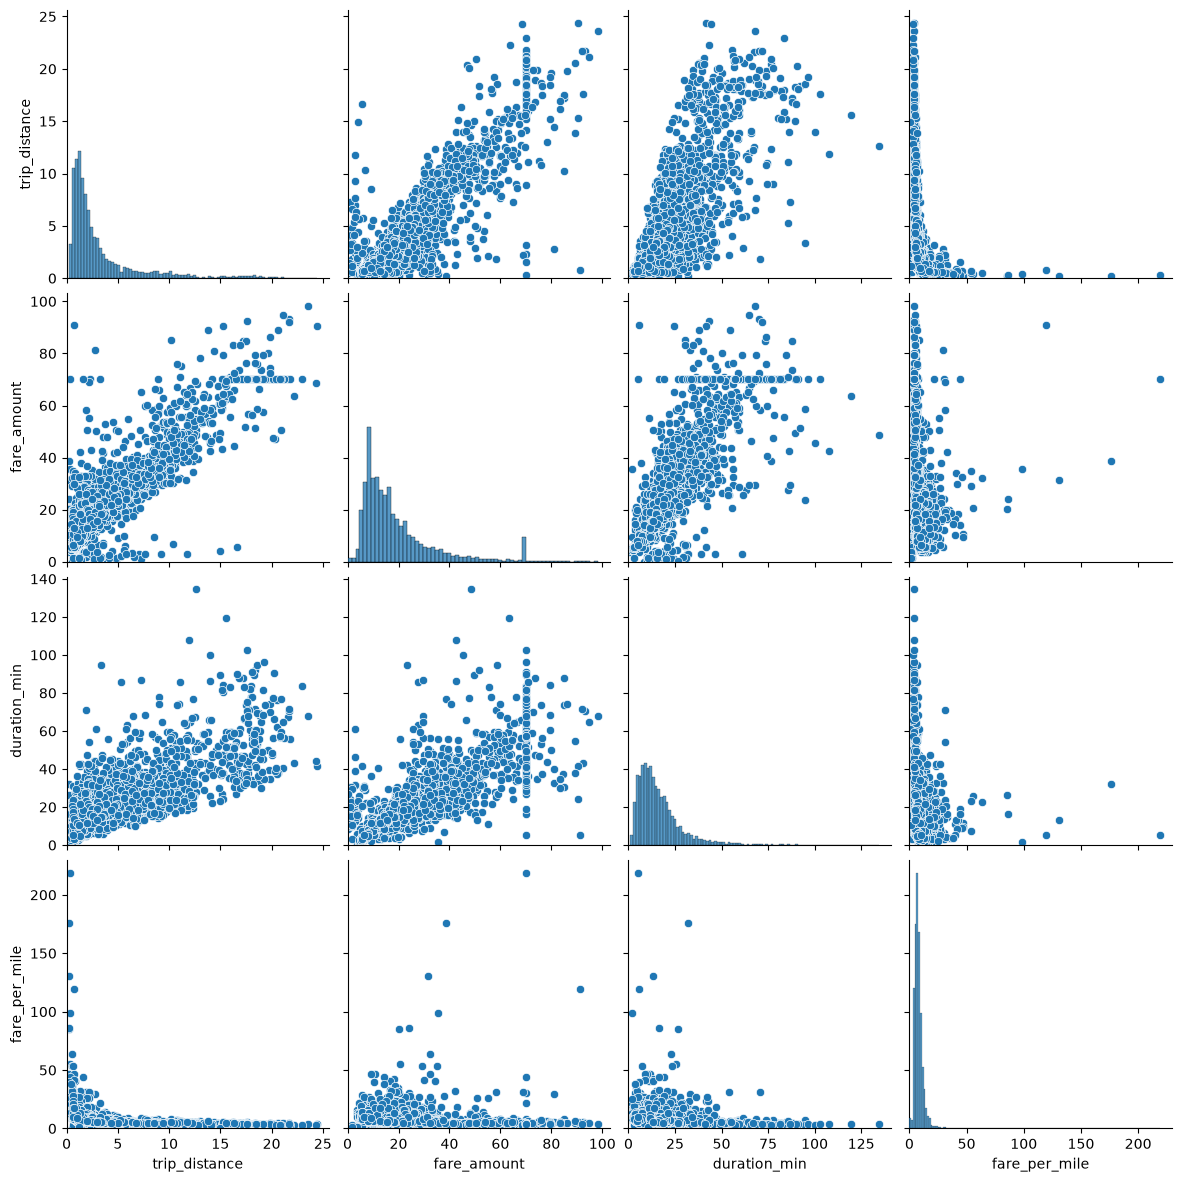

X_train: 0.83 GB | X_test: 0.21 GB
[RAM after split] kernel 10.1 GB | Mac available 11.8 GB
Saved train/test split to model_data/


In [3]:
# EDA
hourly = final.groupby("pickup_hour").agg(
    median_fare=("fare_amount", "median"),
    median_fare_per_mile=("fare_per_mile", "median"),
    median_duration=("duration_min", "median"),
    trips=("fare_amount", "count"),
).reset_index()

plt.figure(figsize=(14, 6))
plt.plot(hourly["pickup_hour"], hourly["median_fare_per_mile"], marker="o", linewidth=2)
plt.xticks(range(0, 24, 2), ["12 AM", "2 AM", "4 AM", "6 AM", "8 AM", "10 AM",
                             "12 PM", "2 PM", "4 PM", "6 PM", "8 PM", "10 PM"])
plt.xlabel("Pickup Time"); plt.ylabel("Median Fare per Mile ($)")
plt.title("Median Fare per Mile by Pickup Time")
plt.tight_layout(); plt.show()

sample = final.sample(n=10_000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="trip_distance", y="fare_amount", alpha=0.1, s=10)
plt.xlim(0, 25); plt.title("Fare Amount vs. Trip Distance"); plt.show()

plt.figure(figsize=(10, 6))
plt.hist(final["trip_distance"], bins=100)
plt.xlabel("Trip Distance (miles)"); plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Distances"); plt.show()

# Hypothesis 4: multicollinearity
g = sns.pairplot(
    sample[["trip_distance", "fare_amount", "duration_min", "fare_per_mile"]].head(5000),
    height=3,
)
for ax in g.axes.flat:
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)
plt.show()

# %% 4. Train / test split
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

TARGET = "fare_amount"
CAT_COLS = ["VendorID", "PULocationID", "DOLocationID"]
NUM_COLS = ["pickup_hour", "pickup_month", "pickup_day", "trip_distance", "duration_min"]
FEATURES = CAT_COLS + NUM_COLS

X_train, X_test, y_train, y_test = train_test_split(
    final[FEATURES], final[TARGET], test_size=0.2, random_state=42
)

# ---- Memory management --------------------------------------------------------
import gc
import joblib
from pathlib import Path

# The full cleaned table (~3.5 GB) is only needed for EDA; every model below uses
# X_train/X_test, which are separate copies. Free it and the EDA leftovers.
del final, sample, hourly, g
plt.close("all")

# Smaller dtypes for the features: zone/vendor IDs fit in int16/int8, hours/days/
# months in int8, and float32 is plenty for miles and minutes. Roughly halves the
# size of X_train/X_test. (Targets stay float64 so the metrics are unchanged.)
SMALL_DTYPES = {
    "VendorID": "int8", "PULocationID": "int16", "DOLocationID": "int16",
    "pickup_hour": "int8", "pickup_month": "int8", "pickup_day": "int8",
    "trip_distance": "float32", "duration_min": "float32",
}
X_train = X_train.astype(SMALL_DTYPES)
X_test = X_test.astype(SMALL_DTYPES)
gc.collect()
print(f"X_train: {X_train.memory_usage(deep=True).sum() / 1e9:.2f} GB | "
      f"X_test: {X_test.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# Big models (random forest, XGBoost) are saved to disk right after they're
# evaluated and deleted from RAM, then reloaded one at a time when needed later.
MODEL_DIR = Path("saved_models")
MODEL_DIR.mkdir(exist_ok=True)

def save_model(model, name):
    path = MODEL_DIR / f"{name}.joblib"
    joblib.dump(model, path, compress=3)
    print(f"Saved {name} -> {path} ({path.stat().st_size / 1e6:.0f} MB on disk)")

def load_model(name):
    return joblib.load(MODEL_DIR / f"{name}.joblib")

def subsample(X, y, n, seed=42):
    """Random n-row sample WITHOUT copying the rest of the data.
    (train_test_split(..., train_size=n) also builds a copy of all the leftover
    rows, which briefly doubles memory before being thrown away.)"""
    if n >= len(X):
        return X, y
    idx = np.sort(np.random.default_rng(seed).choice(len(X), size=n, replace=False))
    return X.iloc[idx], y.iloc[idx]

def predict_chunked(model, X, chunk=1_000_000):
    """Predict in chunks so large intermediate arrays never exist all at once."""
    return np.concatenate([model.predict(X.iloc[i:i + chunk]) for i in range(0, len(X), chunk)])

try:
    import psutil
    def print_ram(label=""):
        used = psutil.Process().memory_info().rss / 1e9
        free = psutil.virtual_memory().available / 1e9
        print(f"[RAM {label}] kernel {used:.1f} GB | Mac available {free:.1f} GB")
except ImportError:   # run  %pip install psutil  to enable
    def print_ram(label=""):
        pass

print_ram("after split")

# Save the exact split so the neural net can be trained in its own notebook
# (NYC-NN.ipynb) with a fresh kernel: no XGBoost, forest or full dataset in RAM.
DATA_DIR = Path("model_data")
DATA_DIR.mkdir(exist_ok=True)
X_train.to_parquet(DATA_DIR / "X_train.parquet")
X_test.to_parquet(DATA_DIR / "X_test.parquet")
y_train.to_frame().to_parquet(DATA_DIR / "y_train.parquet")
y_test.to_frame().to_parquet(DATA_DIR / "y_test.parquet")
print(f"Saved train/test split to {DATA_DIR}/")

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

results = {}
results = {}
preds = {}

def evaluate(name, pred):
    pred = np.asarray(pred).reshape(-1)

    if len(pred) != len(y_test):
        raise ValueError(f"{name}: predictions don't match y_test")

    preds[name] = pred.astype("float32")   # float32 halves the memory per model

    results[name] = {
        "RMSE": rmse(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
    }

    print(name, {
        k: round(v, 4)
        for k, v in results[name].items()
    })

In [4]:
# %% 5a. Model 1: Linear regression (one-hot categoricals + scaled numerics)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

linear = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ])),
    ("reg", LinearRegression()),
])
linear.fit(X_train, y_train)
evaluate("Linear", linear.predict(X_test))


Linear {'RMSE': np.float64(5.5722), 'MAE': 3.3789, 'R2': 0.8661}


In [5]:
from sklearn.base import clone
from sklearn.linear_model import Lasso, LassoCV

# Choose alpha by 3-fold CV on a subsample (LassoCV on the full data is slow),
# then refit a single Lasso with that alpha on the full training set.
LASSO_CV_ROWS = 1_000_000
cv_X, cv_y = subsample(X_train, y_train, LASSO_CV_ROWS)
lasso_cv = Pipeline([
    ("prep", clone(linear.named_steps["prep"])),
    ("reg", LassoCV(alphas=30, cv=3, max_iter=5000, n_jobs=-1, random_state=42)),
])
lasso_cv.fit(cv_X, cv_y)
best_alpha = lasso_cv.named_steps["reg"].alpha_
print(f"Lasso alpha chosen by CV: {best_alpha:.6f}")
del cv_X, cv_y, lasso_cv

lasso = Pipeline([
    ("prep", clone(linear.named_steps["prep"])),
    ("reg", Lasso(alpha=best_alpha, max_iter=5000)),
])
lasso.fit(X_train, y_train)
evaluate("Lasso", lasso.predict(X_test))

# Which inputs did Lasso keep? (counts nonzero coefficients per original feature)
lasso_coef = lasso.named_steps["reg"].coef_
lasso_names = lasso.named_steps["prep"].get_feature_names_out()   # e.g. "cat__PULocationID_132"
kinds, cols = zip(*(n.split("__", 1) for n in lasso_names))
groups = [c.rsplit("_", 1)[0] if k == "cat" else c for k, c in zip(kinds, cols)]
selection = (pd.DataFrame({"feature": groups, "kept": lasso_coef != 0})
             .groupby("feature")["kept"].agg(kept="sum", total="size"))
print("\nLasso feature selection (nonzero coefficients / total columns):")
print(selection)

Lasso alpha chosen by CV: 0.014028
Lasso {'RMSE': np.float64(5.7487), 'MAE': 3.4348, 'R2': 0.8575}

Lasso feature selection (nonzero coefficients / total columns):
               kept  total
feature                   
DOLocationID     16    261
PULocationID     13    262
VendorID          2      3
duration_min      1      1
pickup_day        1      1
pickup_hour       1      1
pickup_month      1      1
trip_distance     1      1


In [6]:
import os
print("Current notebook PID:", os.getpid())

Current notebook PID: 12022


In [7]:
# %% 5c. Higher-order (polynomial) linear regression
# Expands the 5 numeric features into all squares and products, e.g.
# trip_distance², trip_distance × duration_min, duration_min × pickup_hour
# (plus three-way products at degree 3). Zones/vendor stay one-hot exactly as in
# the plain linear model, so the only change is the added curvature/interactions.
# Zones are NOT expanded: zone × zone would mean ~70,000 extra columns.
# Still linear in its coefficients, so it's directly comparable to Linear/Lasso.
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

POLY_DEGREES = [2, 3, 4]        # 5 numerics -> 20 terms at degree 2, 55 at degree 3
POLY_TRAIN_ROWS = 1_000_000  # plenty for ~600 coefficients; full data would need 10-25 GB RAM

# predict_chunked() is defined in the train/test split cell

poly_X, poly_y = subsample(X_train, y_train, POLY_TRAIN_ROWS)

poly_models = {}
for d in POLY_DEGREES:
    model = Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
            ("num", Pipeline([
                ("scale", StandardScaler()),
                ("poly", PolynomialFeatures(degree=d, include_bias=False)),
                ("rescale", StandardScaler()),   # power terms have very different scales
            ]), NUM_COLS),
        ])),
        # A small ridge penalty keeps the highly correlated power terms numerically
        # stable; with millions of rows it barely shrinks anything.
        ("reg", Ridge(alpha=1.0)),
    ])
    model.fit(poly_X, poly_y)
    poly_models[f"Poly{d}"] = model
    evaluate(f"Poly{d}", predict_chunked(model, X_test))

del poly_X, poly_y

Poly2 {'RMSE': np.float64(5.256), 'MAE': 2.9904, 'R2': 0.8809}
Poly3 {'RMSE': np.float64(6.1106), 'MAE': 2.1022, 'R2': 0.839}
Poly4 {'RMSE': np.float64(64.523), 'MAE': 2.064, 'R2': -16.9517}


Linear: residual skew 1.82, excess kurtosis 22.7
Lasso: residual skew 1.75, excess kurtosis 23.9
Poly2: residual skew 1.77, excess kurtosis 27.2
Poly3: residual skew 0.77, excess kurtosis 80.5
Poly4: residual skew 2.55, excess kurtosis 40.5


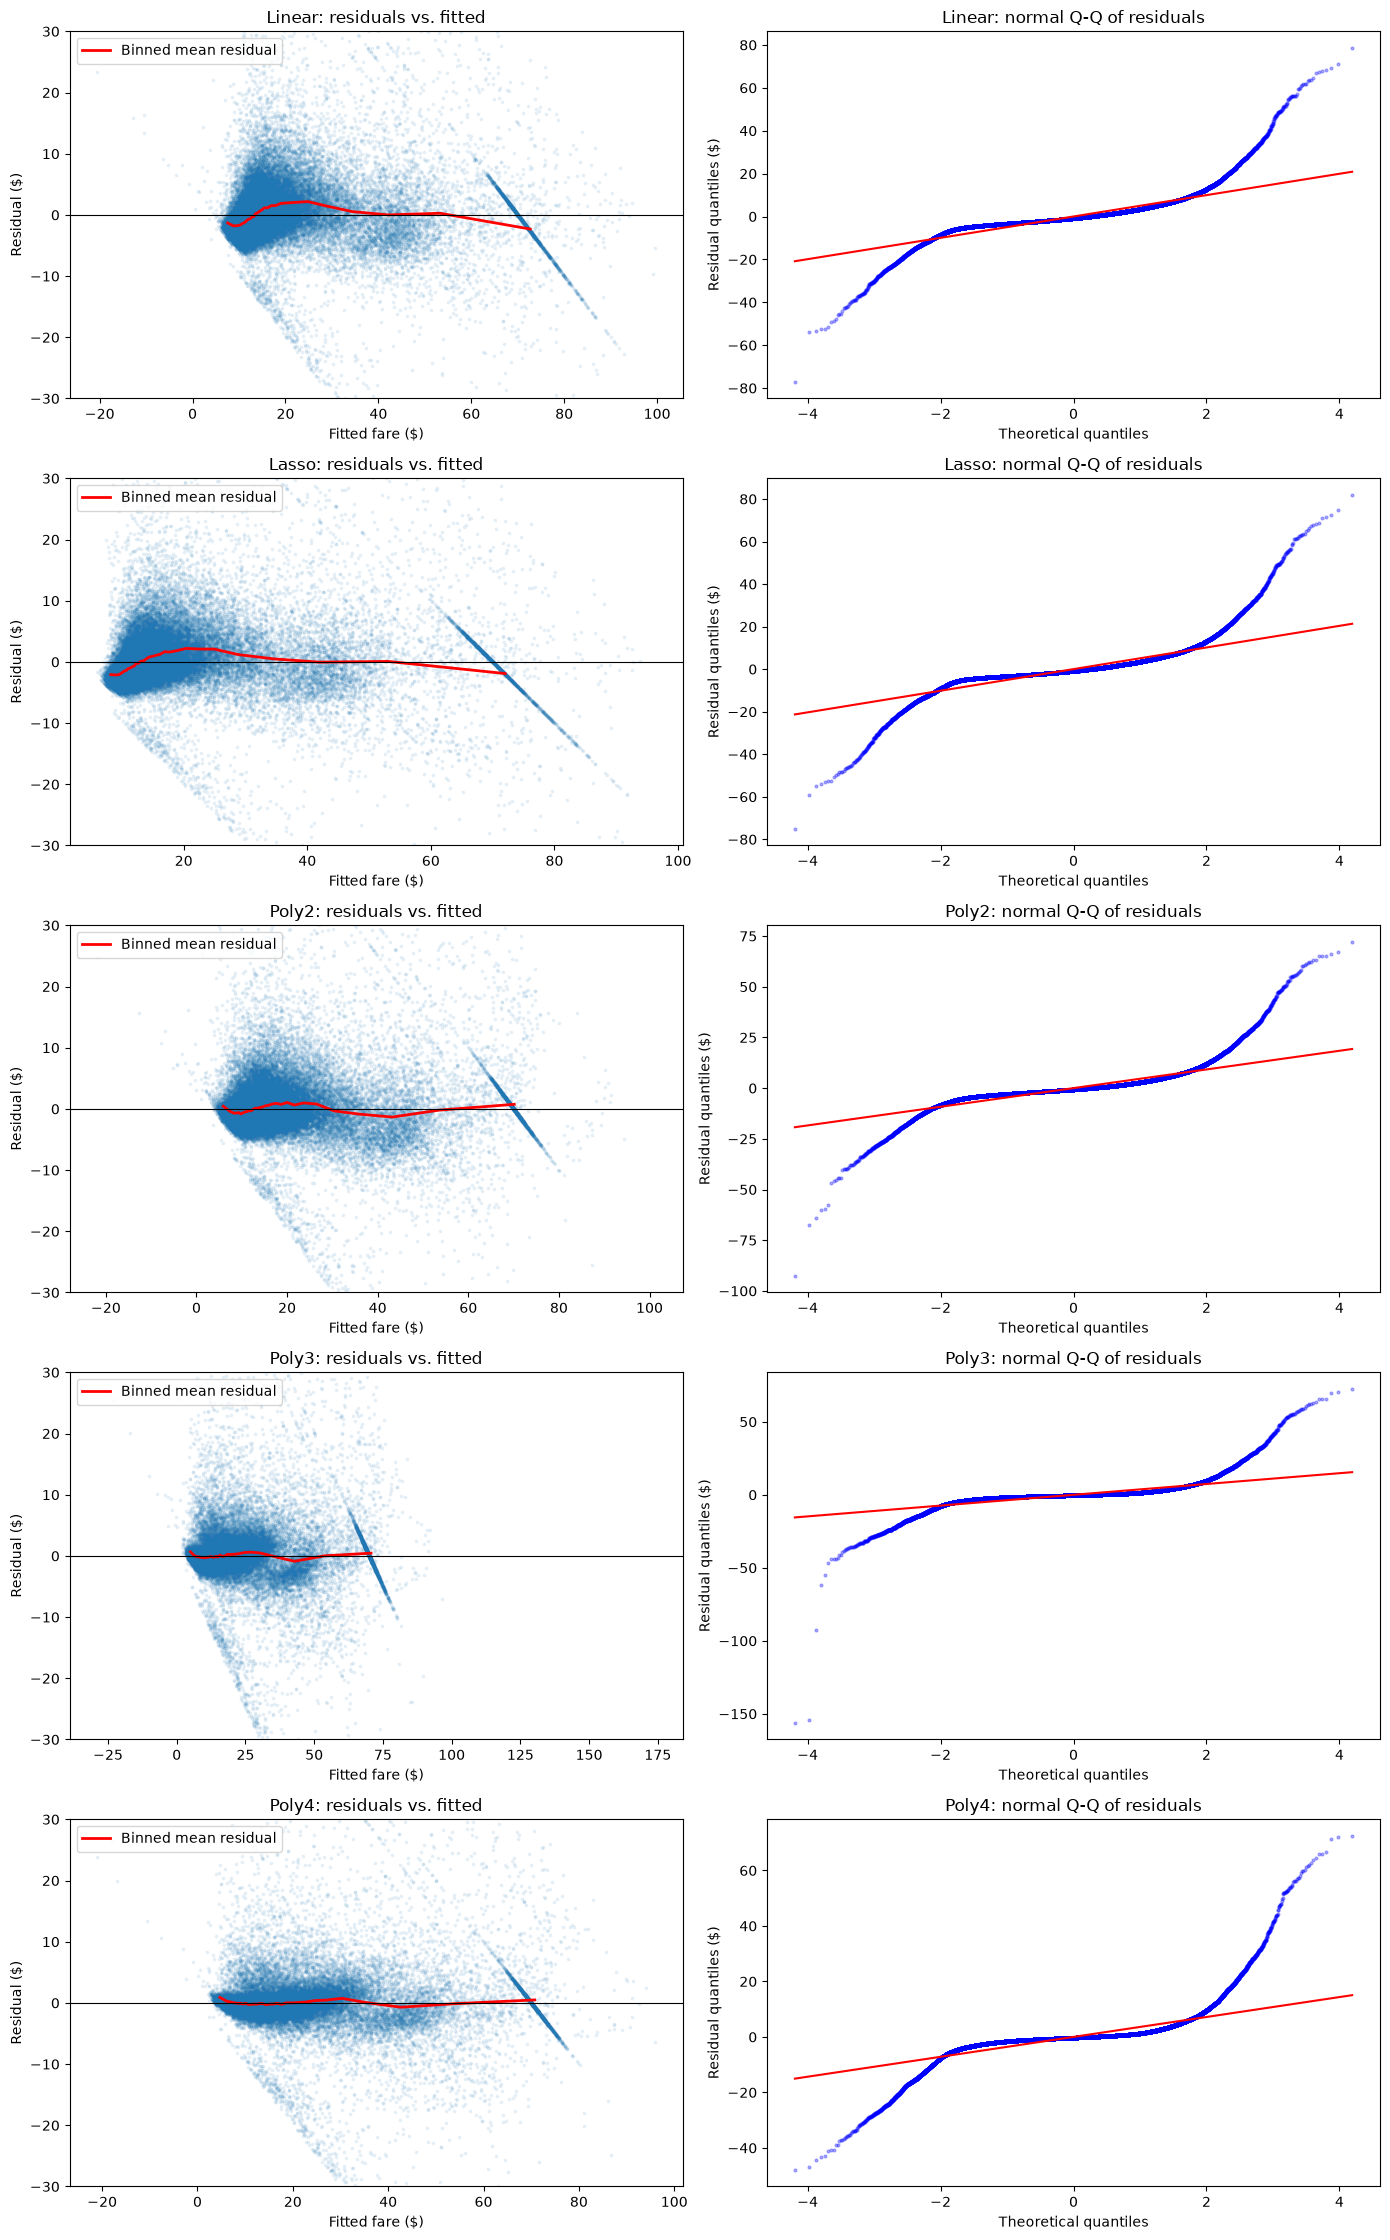

In [8]:
# %% 5d. Residual diagnostics for the linear-family models
# Residuals vs. fitted: ideally a flat, even band around 0.
#   - Red line curving away from 0 = nonlinearity the model is missing.
#   - Band widening to the right (a funnel) = errors grow with fare size
#     (heteroscedasticity).
# Normal Q-Q plot: points on the straight line = normally distributed residuals.
#   - Ends bending away from the line (an S-shape) = heavier tails than normal,
#     i.e. occasional large misses, which is what pushes RMSE well above MAE.
# Plotted on a random test sample: millions of points would add nothing visually.
from scipy import stats

DIAG_ROWS = 50_000
diag_X = X_test.sample(min(DIAG_ROWS, len(X_test)), random_state=1)
diag_y = y_test.loc[diag_X.index].to_numpy()

lin_models = {"Linear": linear, "Lasso": lasso, **poly_models}

fig, axes = plt.subplots(len(lin_models), 2, figsize=(14, 4.5 * len(lin_models)))
for (name, model), (ax_rf, ax_qq) in zip(lin_models.items(), axes):
    fitted = model.predict(diag_X)
    resid = diag_y - fitted

    # Residuals vs. fitted, with a binned-mean line to show systematic bias
    ax_rf.scatter(fitted, resid, s=3, alpha=0.08)
    bins = pd.qcut(fitted, 30, duplicates="drop")
    binned = pd.DataFrame({"f": fitted, "r": resid}).groupby(bins, observed=True).mean()
    ax_rf.plot(binned["f"], binned["r"], color="red", linewidth=2, label="Binned mean residual")
    ax_rf.axhline(0, color="k", linewidth=0.8)
    ax_rf.set_ylim(-30, 30)   # zoomed view; a few larger residuals fall outside
    ax_rf.set_xlabel("Fitted fare ($)"); ax_rf.set_ylabel("Residual ($)")
    ax_rf.set_title(f"{name}: residuals vs. fitted"); ax_rf.legend(loc="upper left")

    # Normal Q-Q plot of the residuals
    stats.probplot(resid, dist="norm", plot=ax_qq)
    ax_qq.get_lines()[0].set(markersize=2, alpha=0.3)
    ax_qq.set_title(f"{name}: normal Q-Q of residuals")
    ax_qq.set_ylabel("Residual quantiles ($)")

    print(f"{name}: residual skew {stats.skew(resid):.2f}, "
          f"excess kurtosis {stats.kurtosis(resid):.1f}")   # normal = 0 and 0

plt.tight_layout(); plt.show()
del diag_X, diag_y

In [9]:
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

XGB_TRAIN_ROWS = 2_000_000

# Sample training rows
xgb_X, xgb_y = subsample(X_train, y_train, XGB_TRAIN_ROWS)

# Reserve 5% for early stopping
xgb_Xtr, xgb_Xval, xgb_ytr, xgb_yval = train_test_split(
    xgb_X,
    xgb_y,
    test_size=0.05,
    random_state=42
)

xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=6,
    tree_method="hist",
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=20,
    n_jobs=4,
    random_state=42,
)

xgb.fit(
    xgb_Xtr,
    xgb_ytr,
    eval_set=[(xgb_Xval, xgb_yval)],
    verbose=50,
)

evaluate("XGBoost", xgb.predict(X_test))

# Free the training copies and move the model to disk
del xgb_X, xgb_y, xgb_Xtr, xgb_Xval, xgb_ytr, xgb_yval
save_model(xgb, "xgboost")
del xgb
gc.collect()

[0]	validation_0-rmse:13.90325
[50]	validation_0-rmse:4.30941
[100]	validation_0-rmse:4.18067
[150]	validation_0-rmse:4.13009
[200]	validation_0-rmse:4.09458
[250]	validation_0-rmse:4.07102
[300]	validation_0-rmse:4.05132
[350]	validation_0-rmse:4.03849
[400]	validation_0-rmse:4.02508
[450]	validation_0-rmse:4.01623
[499]	validation_0-rmse:4.00898
XGBoost {'RMSE': np.float64(4.047), 'MAE': 1.732, 'R2': 0.9294}
Saved xgboost -> saved_models/xgboost.joblib (1 MB on disk)


86

In [10]:
from sklearn.ensemble import RandomForestRegressor

# Why this cell used to crash: scikit-learn keeps every node of every tree in RAM,
# and n_jobs=-1 grows one tree per CPU core at the same time, each with its own
# working buffers. Peak memory therefore grows with (rows per tree / min_samples_leaf)
# x n_estimators, plus the number of trees being built in parallel. Predicting on
# all ~8.7M test rows at once adds another large temporary array on top.
RF_TRAIN_ROWS = 1_000_000   # was 2M; halves the size of every tree
RF_JOBS = 4                 # was -1 (all cores); fewer trees in progress at once

print_ram("before RF")
rf_X, rf_y = subsample(X_train, y_train, RF_TRAIN_ROWS)
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,          # caps memory per tree
    min_samples_leaf=20,   # smooths leaves, also shrinks trees (raise to 50 to shrink more)
    max_features=0.5,      # decorrelates trees (4 of 8 features per split)
    max_samples=0.5,       # bootstrap sample size per tree
    n_jobs=RF_JOBS,
    random_state=42,
)
rf.fit(rf_X, rf_y)
del rf_X, rf_y
gc.collect()
print_ram("after RF fit")

evaluate("RandomForest", predict_chunked(rf, X_test))

# A forest can take 0.5-2 GB of RAM; keep it on disk instead
save_model(rf, "random_forest")
del rf
gc.collect()
print_ram("after RF saved + freed")

[RAM before RF] kernel 5.0 GB | Mac available 19.1 GB
[RAM after RF fit] kernel 5.2 GB | Mac available 18.3 GB
RandomForest {'RMSE': np.float64(4.3392), 'MAE': 1.7363, 'R2': 0.9188}
Saved random_forest -> saved_models/random_forest.joblib (61 MB on disk)
[RAM after RF saved + freed] kernel 3.3 GB | Mac available 19.6 GB


In [15]:
# %% 5f. Neural net: trained in NYC-NN.ipynb, loaded here
# The network itself is small; the crashes came from training it in a kernel that
# already held the data, the other models and XGBoost's threading library. It now
# runs in its own notebook and saves its test-set predictions here.
nn_pred_path = MODEL_DIR / "nn_test_preds.npy"
nn_index_path = MODEL_DIR / "nn_test_index.npy"

if not nn_pred_path.exists():
    print("No neural-net predictions yet: run NYC-NN.ipynb, then re-run this cell and the ones below.")
elif not np.array_equal(np.load(nn_index_path), X_test.index.to_numpy()):
    print("Saved neural-net predictions are for a different test set: re-run NYC-NN.ipynb.")
else:
    evaluate("NeuralNet", np.load(nn_pred_path))

NeuralNet {'RMSE': np.float64(4.0912), 'MAE': 1.7847, 'R2': 0.9278}


                 RMSE     MAE       R2  RMSE rank  MAE rank
XGBoost        4.0470  1.7320   0.9294          1         1
NeuralNet      4.0912  1.7847   0.9278          2         3
RandomForest   4.3392  1.7363   0.9188          3         2
Poly2          5.2560  2.9904   0.8809          4         6
Linear         5.5722  3.3789   0.8661          5         7
Lasso          5.7487  3.4348   0.8575          6         8
Poly3          6.1106  2.1022   0.8390          7         5
Poly4         64.5230  2.0640 -16.9517          8         4

Absolute error quantiles ($):
              0.500  0.900  0.990  0.999
Linear         2.32   6.71  22.15  50.14
Lasso          2.37   6.81  23.04  52.36
Poly2          1.88   6.16  21.56  48.52
Poly3          0.94   4.51  20.55  47.85
Poly4          0.84   4.38  20.38  46.93
XGBoost        0.64   4.00  18.41  41.87
RandomForest   0.57   3.94  19.96  47.28
NeuralNet      0.71   4.09  18.60  41.87

Residual skewness (actual - predicted):
Linear             

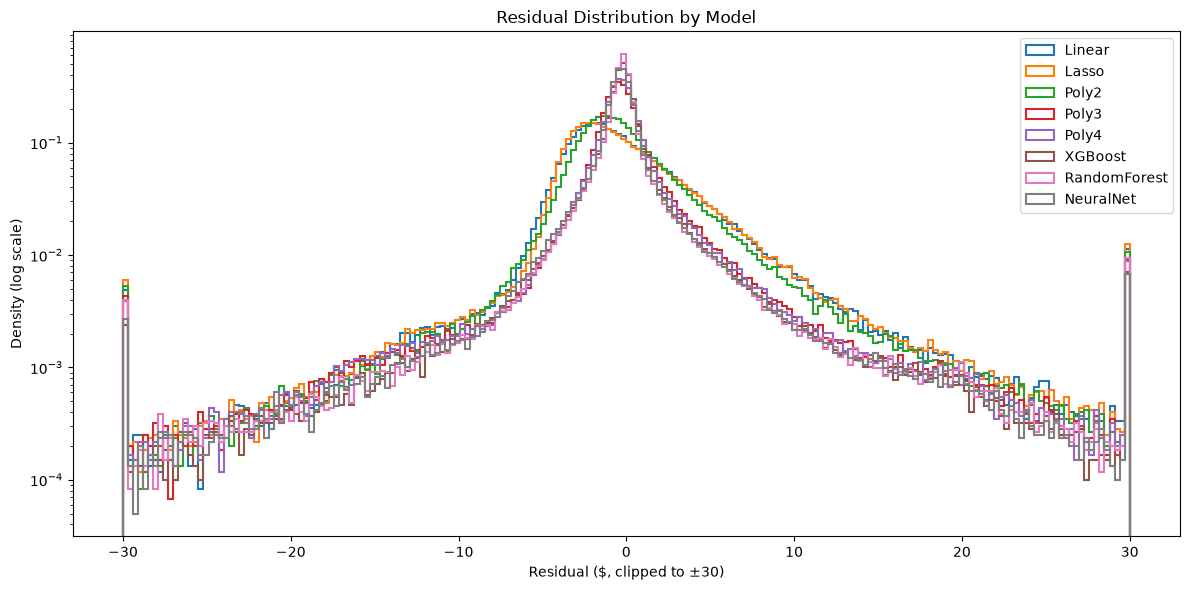

90556

In [16]:
res = pd.DataFrame(results).T
res["RMSE rank"] = res["RMSE"].rank().astype(int)
res["MAE rank"] = res["MAE"].rank().astype(int)
print(res.sort_values("RMSE").round(4))
# If the two rank columns disagree, the models differ mainly in how they handle
# the tail of large errors; look at the diagnostics below before picking a winner.

# %% 6b. Error distribution: are errors skewed?
y_true = y_test.to_numpy(dtype="float32")
abs_err = pd.DataFrame({n: np.abs(y_true - p) for n, p in preds.items()})
print("\nAbsolute error quantiles ($):")
print(abs_err.quantile([0.5, 0.9, 0.99, 0.999]).T.round(2))

resid = pd.DataFrame({n: y_true - p for n, p in preds.items()})
print("\nResidual skewness (actual - predicted):")
print(resid.skew().round(3))

plt.figure(figsize=(12, 6))
resid_sample = resid.sample(200_000, random_state=0)
for name in resid_sample.columns:
    plt.hist(resid_sample[name].clip(-30, 30), bins=200, histtype="step",
             linewidth=1.5, label=name, density=True)
plt.yscale("log")
plt.xlabel("Residual ($, clipped to ±30)"); plt.ylabel("Density (log scale)")
plt.title("Residual Distribution by Model")
plt.legend(); plt.tight_layout(); plt.show()
del abs_err, resid, resid_sample, y_true
gc.collect()

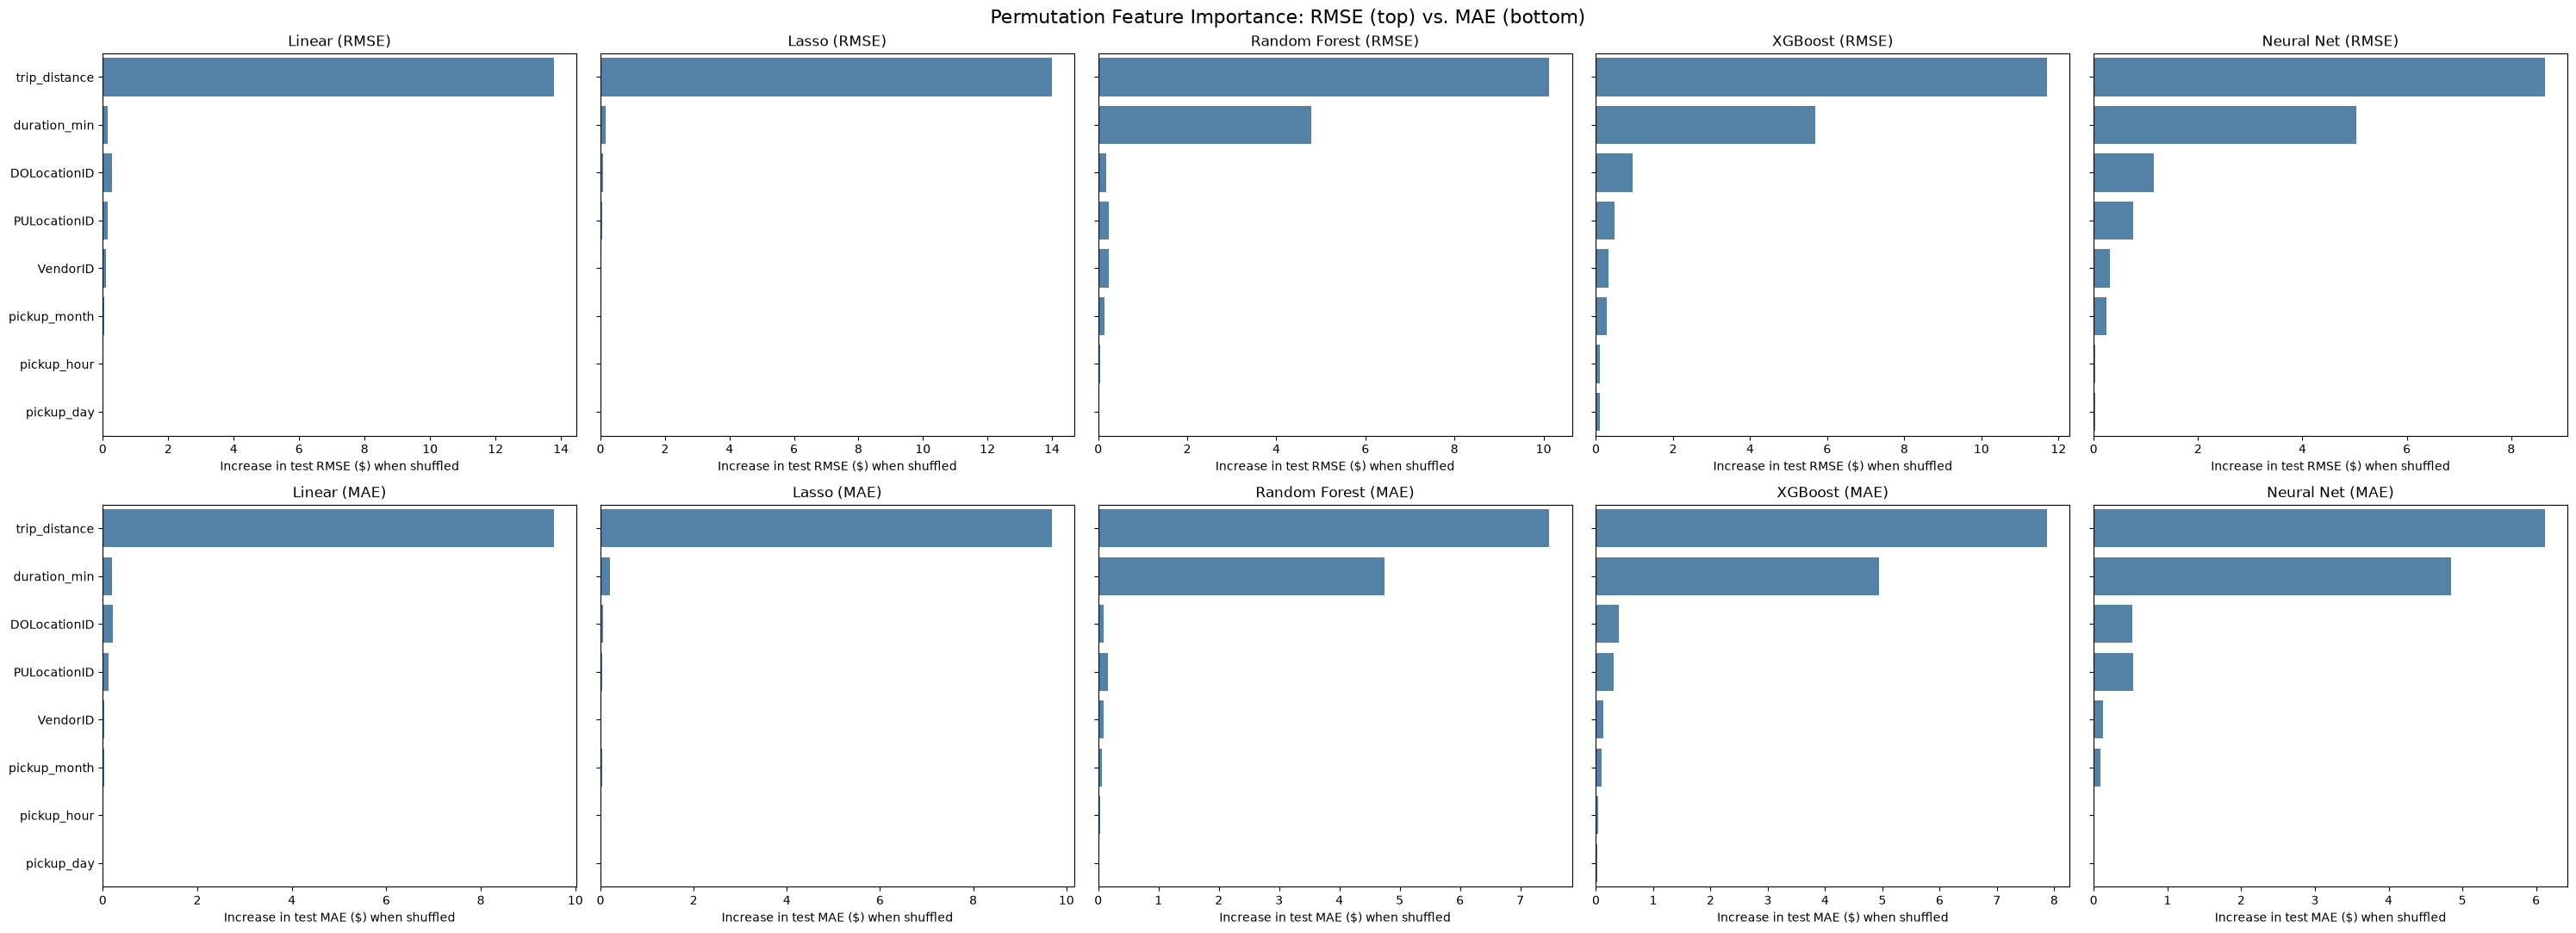

In [17]:
def permutation_importance(predict, X, y, n_repeats=3, seed=42):
    rng = np.random.default_rng(seed)
    base_pred = predict(X)
    base_rmse, base_mae = rmse(y, base_pred), mean_absolute_error(y, base_pred)
    out = {"RMSE": {}, "MAE": {}}
    for col in X.columns:
        r_scores, m_scores = [], []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[col] = rng.permutation(Xp[col].to_numpy())
            p = predict(Xp)
            r_scores.append(rmse(y, p))
            m_scores.append(mean_absolute_error(y, p))
        out["RMSE"][col] = np.mean(r_scores) - base_rmse
        out["MAE"][col] = np.mean(m_scores) - base_mae
    return pd.DataFrame(out)

X_imp = X_test.sample(200_000, random_state=0)
y_imp = y_test.loc[X_imp.index]

# Small models stay in memory; the forest and XGBoost are loaded from disk one
# at a time and freed again, so only one big model is ever in RAM.
model_sources = {
    "Linear": lambda: linear,
    "Lasso": lambda: lasso,
    "Random Forest": lambda: load_model("random_forest"),
    "XGBoost": lambda: load_model("xgboost"),
}
imp = {}
for name, get_model in model_sources.items():
    m = get_model()
    imp[name] = permutation_importance(m.predict, X_imp, y_imp)
    del m
    gc.collect()
# Neural-net importance is computed in NYC-NN.ipynb on the same 200k-row sample
nn_imp_path = MODEL_DIR / "nn_importance.parquet"
if nn_imp_path.exists():
    imp["Neural Net"] = pd.read_parquet(nn_imp_path)
else:
    print("Neural-net importance not found: run NYC-NN.ipynb to include it.")
models = imp   # used below for the number of plot columns
imp_rmse = pd.DataFrame({n: d["RMSE"] for n, d in imp.items()})
imp_mae = pd.DataFrame({n: d["MAE"] for n, d in imp.items()})
order = imp_rmse.mean(axis=1).sort_values(ascending=False).index  # same order in both rows

fig, axes = plt.subplots(2, len(models), figsize=(6 * len(models), 11), sharey=True)
for row, (metric, tbl) in enumerate([("RMSE", imp_rmse), ("MAE", imp_mae)]):
    for ax, model_name in zip(axes[row], tbl.columns):
        sns.barplot(x=tbl.loc[order, model_name], y=order, ax=ax, color="steelblue")
        ax.set_title(f"{model_name} ({metric})")
        ax.set_xlabel(f"Increase in test {metric} ($) when shuffled")
        ax.set_ylabel("")
fig.suptitle("Permutation Feature Importance: RMSE (top) vs. MAE (bottom)", fontsize=16)
plt.tight_layout(); plt.show()

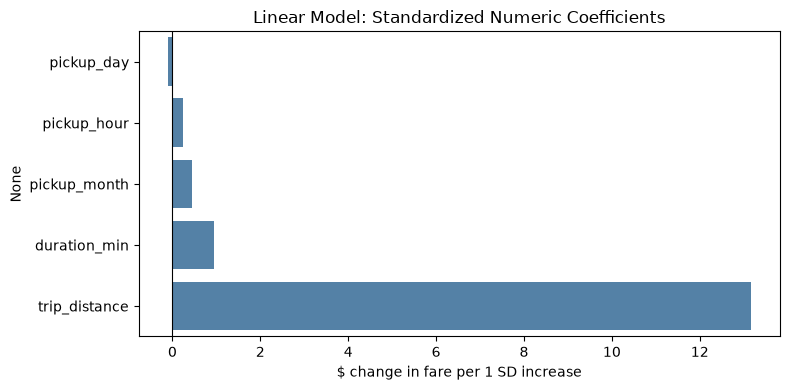

In [18]:
coefs = pd.Series(
    linear.named_steps["reg"].coef_[-len(NUM_COLS):], index=NUM_COLS
).sort_values()
plt.figure(figsize=(8, 4))
sns.barplot(x=coefs.values, y=coefs.index, color="steelblue")
plt.axvline(0, color="k", linewidth=0.8)
plt.xlabel("$ change in fare per 1 SD increase")
plt.title("Linear Model: Standardized Numeric Coefficients")
plt.tight_layout(); plt.show()